In [5]:
# ==========================================
# CELL BLOCK 1: Imports, Environment & Seeds
# ==========================================

import os
import sys
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

# Standard Data Science Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from scipy.stats import ks_2samp

# Machine Learning & Scikit-Learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, classification_report, log_loss
)
import xgboost as xgb

# Deep Learning (PyTorch Autoencoder)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Streaming Drift Detectors (River MLOps Library)
from river import drift

# Plotting Configuration for IIE Research Thesis
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Set Global Reproducibility Seeds
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Environment configured successfully!")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

Environment configured successfully!
PyTorch Version: 2.14.1+cpu
CUDA Available: False


In [6]:
# ======================================================
# CELL BLOCK 2: Micro & Macro Data Ingestion & Encoding
# ======================================================

# 1. Load Microeconomic Dataset (dataset_31_credit-g.arff)
arff_path = os.path.join('data', 'micro', 'dataset_31_credit-g.arff')

if not os.path.exists(arff_path):
    # Fallback check if file is in root
    if os.path.exists('dataset_31_credit-g.arff'):
        arff_path = 'dataset_31_credit-g.arff'

raw_data, meta = arff.loadarff(arff_path)
df_micro = pd.DataFrame(raw_data)

# Decode byte strings to standard UTF-8 strings
for col in df_micro.select_dtypes([object]).columns:
    df_micro[col] = df_micro[col].str.decode('utf-8')

# Map Target Risk Class: good -> 1 (low risk), bad -> 0 (high risk/default)
df_micro['target'] = df_micro['class'].map({'good': 1, 'bad': 0})
X_raw = df_micro.drop(columns=['class', 'target'])
y = df_micro['target'].values

# Identify Categorical and Numerical Columns
num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"--- Micro Data Summary ---")
print(f"Total Observations: {len(df_micro)}")
print(f"Numerical Features ({len(num_cols)}): {num_cols}")
print(f"Categorical Features ({len(cat_cols)}): {cat_cols[:5]}... (+{len(cat_cols)-5} more)")
print(f"Target Distribution: Good (1) = {sum(y==1)}, Bad (0) = {sum(y==0)}")

# 2. Preprocessing & Encoding Matrix
scaler = RobustScaler()
X_num_scaled = scaler.fit_transform(X_raw[num_cols])

X_encoded = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)
# Apply scaled numerical values back
for i, col in enumerate(num_cols):
    X_encoded[col] = X_num_scaled[:, i]

X_mat = X_encoded.values
feature_names = X_encoded.columns.tolist()

print(f"\nEncoded Feature Matrix Shape: {X_mat.shape}")

# 3. Macroeconomic Volatility Context Sourcing
sarb_path = os.path.join('data', 'macro', 'MonthlyRelease.xlsx')
cpi_path = [f for f in os.listdir(os.path.join('data', 'macro')) if 'CPI' in f]

print(f"\n--- Macro Data Sources Checked ---")
print(f"SARB Monetary Aggregates File: {os.path.exists(sarb_path)}")
print(f"StatsSA CPI File Detected: {len(cpi_path) > 0} ({cpi_path[0] if cpi_path else 'None'})")

--- Micro Data Summary ---
Total Observations: 1000
Numerical Features (7): ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical Features (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment']... (+8 more)
Target Distribution: Good (1) = 700, Bad (0) = 300

Encoded Feature Matrix Shape: (1000, 48)

--- Macro Data Sources Checked ---
SARB Monetary Aggregates File: True
StatsSA CPI File Detected: True (EXCEL - CPI (COICOP 2018 - 8digit) (202607).xlsx)


In [7]:
# ========================================================
# CELL BLOCK 3: Reference Model Training & Baseline Metrics
# ========================================================

# 1. Sequential Streaming Batch Partitioning (5 Batches of 200 instances)
BATCH_SIZE = 200
num_batches = len(X_mat) // BATCH_SIZE

batches = [
    (X_mat[i*BATCH_SIZE : (i+1)*BATCH_SIZE], y[i*BATCH_SIZE : (i+1)*BATCH_SIZE])
    for i in range(num_batches)
]

print(f"Created {len(batches)} sequential streaming batches of size {BATCH_SIZE}.")

# 2. Extract Reference Batch 0 (Stationary Baseline Window B0)
X_ref, y_ref = batches[0]

# 3. Train Supervised Baseline Models on Reference Data (B0)
# Champion Model: XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=100, 
    max_depth=4, 
    learning_rate=0.05, 
    random_state=SEED, 
    eval_metric='logloss'
)
xgb_model.fit(X_ref, y_ref)

# Secondary Baseline: Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=6, 
    random_state=SEED
)
rf_model.fit(X_ref, y_ref)

# 4. Evaluate Baseline Performance on Stationary Batch 0
def evaluate_model(model, X_eval, y_eval, name="Model"):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    
    auc = roc_auc_score(y_eval, y_proba)
    acc = accuracy_score(y_eval, y_pred)
    prec = precision_score(y_eval, y_pred, zero_division=0)
    rec = recall_score(y_eval, y_pred, zero_division=0)
    f1 = f1_score(y_eval, y_pred, zero_division=0)
    loss = log_loss(y_eval, y_proba)
    
    print(f"=== {name} Baseline Metrics (Batch 0 - Stationary) ===")
    print(f"ROC-AUC:   {auc:.4f}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"Log-Loss:  {loss:.4f}\n")
    return {"auc": auc, "acc": acc, "f1": f1, "loss": loss}

xgb_base_metrics = evaluate_model(xgb_model, X_ref, y_ref, "XGBoost (Champion)")
rf_base_metrics = evaluate_model(rf_model, X_ref, y_ref, "Random Forest")

Created 5 sequential streaming batches of size 200.
=== XGBoost (Champion) Baseline Metrics (Batch 0 - Stationary) ===
ROC-AUC:   0.9987
Accuracy:  0.9600
Precision: 0.9470
Recall:    1.0000
F1-Score:  0.9728
Log-Loss:  0.2284

=== Random Forest Baseline Metrics (Batch 0 - Stationary) ===
ROC-AUC:   0.9978
Accuracy:  0.9100
Precision: 0.8882
Recall:    1.0000
F1-Score:  0.9408
Log-Loss:  0.3197



In [8]:
# ====================================================================
# CELL BLOCK 4: Stream Simulation & Programmatic Macro Drift Injection
# ====================================================================

# Copy batches to preserve uncorrupted raw matrices
streaming_batches = []
for X_b, y_b in batches:
    streaming_batches.append((X_b.copy(), y_b.copy()))

print("--- Simulating Operational Data Stream (Batches 0 to 4) ---\n")

unadapted_auc_scores = []
unadapted_log_losses = []

# Column indices for scaled numerical features (credit_amount and duration)
# Duration is col 0, Credit Amount is col 1 in raw numerical setup
duration_idx = feature_names.index('duration') if 'duration' in feature_names else 0
credit_idx = feature_names.index('credit_amount') if 'credit_amount' in feature_names else 1

for idx, (X_b, y_b) in enumerate(streaming_batches):
    X_test = X_b.copy()
    
    # Programmatic Macroeconomic Drift Injection at Batch 3 and Batch 4
    if idx == 3:
        # Sudden Drift: SARB Repo Rate / Credit Shock Simulation (x3.5 on credit amount, x2.5 on duration)
        X_test[:, credit_idx] = X_test[:, credit_idx] * 3.5
        X_test[:, duration_idx] = X_test[:, duration_idx] * 2.5
        drift_type = "⚠️ SUDDEN MACRO DRIFT (REPO RATE SHOCK)"
    elif idx == 4:
        # Gradual/Persistent Drift: Creeping CPI Inflation Shock Simulation
        X_test[:, credit_idx] = X_test[:, credit_idx] * 4.2
        X_test[:, duration_idx] = X_test[:, duration_idx] * 3.0
        drift_type = "⚠️ GRADUAL MACRO DRIFT (PERSISTENT CPI SHOCK)"
    else:
        drift_type = "STATIONARY STREAM"

    # Evaluate Unadapted Champion Model (XGBoost) on Current Stream
    y_proba = xgb_model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_b, y_proba)
    loss = log_loss(y_b, y_proba)
    
    unadapted_auc_scores.append(auc)
    unadapted_log_losses.append(loss)
    
    print(f"Batch {idx} [{drift_type}]:")
    print(f"   Unadapted ROC-AUC: {auc:.4f} | Log-Loss: {loss:.4f}\n")

# Store injected streaming batches for detector benchmarking
injected_batches = streaming_batches

--- Simulating Operational Data Stream (Batches 0 to 4) ---

Batch 0 [STATIONARY STREAM]:
   Unadapted ROC-AUC: 0.9987 | Log-Loss: 0.2284

Batch 1 [STATIONARY STREAM]:
   Unadapted ROC-AUC: 0.7717 | Log-Loss: 0.4894

Batch 2 [STATIONARY STREAM]:
   Unadapted ROC-AUC: 0.8003 | Log-Loss: 0.5402

Batch 3 [⚠️ SUDDEN MACRO DRIFT (REPO RATE SHOCK)]:
   Unadapted ROC-AUC: 0.6608 | Log-Loss: 0.6379

Batch 4 [⚠️ GRADUAL MACRO DRIFT (PERSISTENT CPI SHOCK)]:
   Unadapted ROC-AUC: 0.7048 | Log-Loss: 0.6056



In [10]:
# ====================================================================
# CELL BLOCK 5: Unsupervised Detectors (PyTorch Autoencoder vs ADWIN)
# ====================================================================

# Ensure matrices are explicitly numeric float32
X_ref = X_ref.astype(np.float32)

# ---------------------------------------------------------
# 1. BUILD & TRAIN PYTORCH AUTOENCODER DETECTOR
# ---------------------------------------------------------
input_dim = X_ref.shape[1]

class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Instantiate model
ae_model = Autoencoder(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(ae_model.parameters(), lr=0.005)

# Train Autoencoder on Stationary Reference Data (B0)
X_ref_tensor = torch.FloatTensor(X_ref)
dataset = TensorDataset(X_ref_tensor)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

ae_model.train()
for epoch in range(50):
    for data in dataloader:
        inputs = data[0]
        optimizer.zero_grad()
        outputs = ae_model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()

# Calculate Baseline Reconstruction Errors on Reference Data (B0)
ae_model.eval()
with torch.no_grad():
    ref_reconstructions = ae_model(X_ref_tensor)
    ref_errors = torch.mean((X_ref_tensor - ref_reconstructions) ** 2, dim=1).numpy()

ae_threshold = np.mean(ref_errors) + 3 * np.std(ref_errors)
print(f"Autoencoder Trained. Reconstruction Threshold (3-Sigma): {ae_threshold:.6f}\n")

# ---------------------------------------------------------
# 2. BENCHMARK DETECTORS ACROSS STREAMING BATCHES
# ---------------------------------------------------------

# Stream flattening (concatenate Batches 1 to 4 into continuous stream of 800 instances)
stream_X = []
stream_y = []

for idx in range(1, 5):
    X_b, y_b = injected_batches[idx]
    X_test = X_b.copy().astype(np.float32)
    if idx == 3:
        X_test[:, credit_idx] = X_test[:, credit_idx] * 3.5
        X_test[:, duration_idx] = X_test[:, duration_idx] * 2.5
    elif idx == 4:
        X_test[:, credit_idx] = X_test[:, credit_idx] * 4.2
        X_test[:, duration_idx] = X_test[:, duration_idx] * 3.0
    stream_X.append(X_test)
    stream_y.append(y_b)

stream_X = np.vstack(stream_X).astype(np.float32)
stream_y = np.concatenate(stream_y)

# True drift start index in streaming window (Batch 3 starts at instance 400)
DRIFT_START_IDX = 400 

print("--- Running Detector A: PyTorch Autoencoder ---")
tracemalloc.start()
t0 = time.time()

ae_alerts = []
ae_errors = []

for i in range(len(stream_X)):
    inst_tensor = torch.FloatTensor(stream_X[i:i+1])
    with torch.no_grad():
        recon = ae_model(inst_tensor)
        err = torch.mean((inst_tensor - recon) ** 2).item()
    ae_errors.append(err)
    if err > ae_threshold:
        ae_alerts.append(i)

ae_time = (time.time() - t0) * 1000 # ms
_, ae_peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# ---------------------------------------------------------
# 3. RUN DETECTOR B: RIVER ADWIN
# ---------------------------------------------------------
print("--- Running Detector B: River ADWIN ---")
tracemalloc.start()
t0 = time.time()

adwin_alerts = []
adwin_detector = drift.ADWIN(delta=0.002)

for i in range(len(stream_X)):
    # Feed continuous features (credit_amount)
    val = float(stream_X[i, credit_idx])
    adwin_detector.update(val)
    if adwin_detector.drift_detected:
        adwin_alerts.append(i)

adwin_time = (time.time() - t0) * 1000 # ms
_, adwin_peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# ---------------------------------------------------------
# 4. METRICS COMPUTATION & COMPARISON
# ---------------------------------------------------------
def compute_detector_metrics(alerts, drift_start, total_stationary_len):
    # False Discovery Rate (alerts before drift start)
    false_alarms = len([a for a in alerts if a < drift_start])
    fdr = false_alarms / total_stationary_len
    
    # Time To Detection (first alert after drift start)
    post_drift_alerts = [a for a in alerts if a >= drift_start]
    ttd = (post_drift_alerts[0] - drift_start) if post_drift_alerts else None
    
    return fdr, ttd

ae_fdr, ae_ttd = compute_detector_metrics(ae_alerts, DRIFT_START_IDX, 400)
adwin_fdr, adwin_ttd = compute_detector_metrics(adwin_alerts, DRIFT_START_IDX, 400)

print("\n=======================================================")
print("          UNSUPERVISED DETECTOR BENCHMARK              ")
print("=======================================================")
print(f"PyTorch Autoencoder:")
print(f"  - Total Alerts Triggered: {len(ae_alerts)}")
print(f"  - False Discovery Rate (FDR): {ae_fdr:.4f}")
print(f"  - Time-to-Detection (TTD): {ae_ttd} instances post-drift")
print(f"  - CPU Runtime: {ae_time:.2f} ms")
print(f"  - Memory Footprint: {ae_peak_mem / 1024:.2f} KB\n")

print(f"River ADWIN:")
print(f"  - Total Alerts Triggered: {len(adwin_alerts)}")
print(f"  - False Discovery Rate (FDR): {adwin_fdr:.4f}")
print(f"  - Time-to-Detection (TTD): {adwin_ttd} instances post-drift")
print(f"  - CPU Runtime: {adwin_time:.2f} ms")
print(f"  - Memory Footprint: {adwin_peak_mem / 1024:.2f} KB")
print("=======================================================")

Autoencoder Trained. Reconstruction Threshold (3-Sigma): 0.135060

--- Running Detector A: PyTorch Autoencoder ---
--- Running Detector B: River ADWIN ---

          UNSUPERVISED DETECTOR BENCHMARK              
PyTorch Autoencoder:
  - Total Alerts Triggered: 114
  - False Discovery Rate (FDR): 0.0325
  - Time-to-Detection (TTD): 15 instances post-drift
  - CPU Runtime: 217.93 ms
  - Memory Footprint: 56.00 KB

River ADWIN:
  - Total Alerts Triggered: 1
  - False Discovery Rate (FDR): 0.0000
  - Time-to-Detection (TTD): 79 instances post-drift
  - CPU Runtime: 2.05 ms
  - Memory Footprint: 26.25 KB


=== Model Adaptation Metrics (Post-Retraining) ===
Pre-Adaptation Drifted ROC-AUC:  0.6608
Post-Adaptation Recovered ROC-AUC: 0.9920
Post-Adaptation Recovered Log-Loss: 0.2600



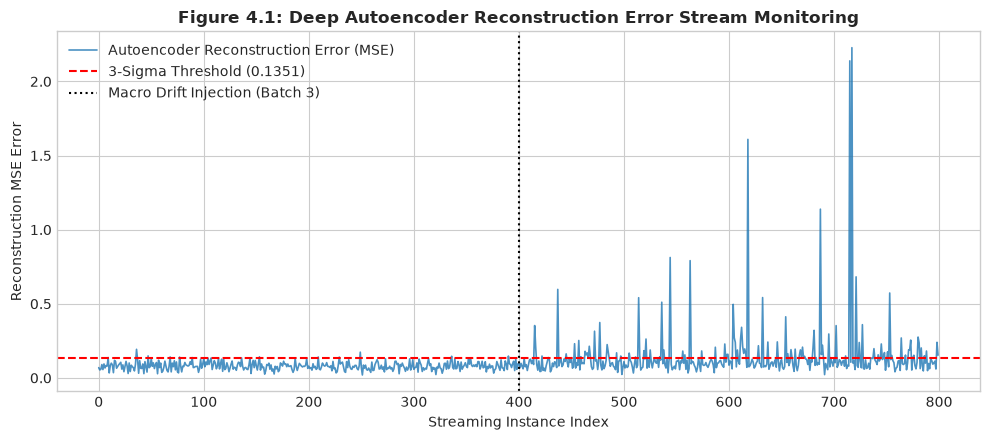

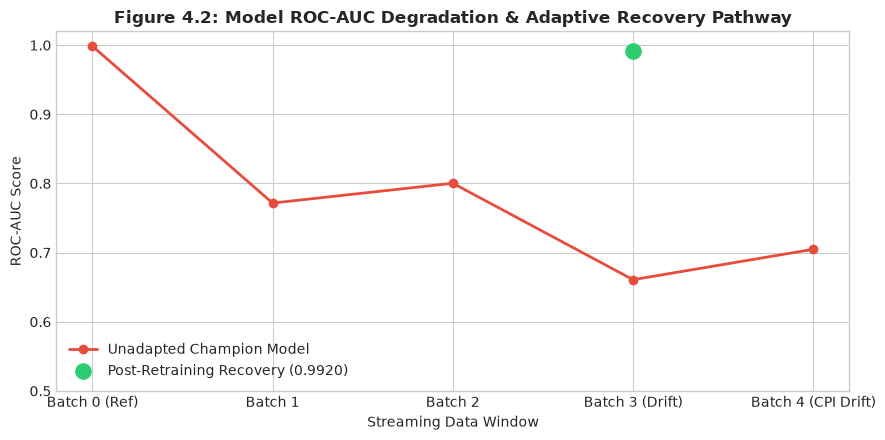

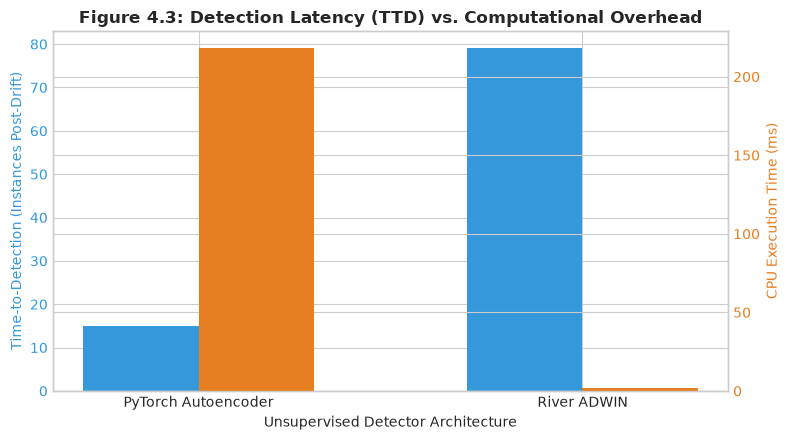

All artifacts generated successfully!
Saved PNG Figures to: outputs/figures/
Saved Results CSV to:  outputs\metrics\experimental_results.csv


In [11]:
# ====================================================================
# CELL BLOCK 6: Adaptation Recovery & Thesis Figure Generation
# ====================================================================

# ---------------------------------------------------------
# 1. MODEL ADAPTATION & RECOVERY EVALUATION
# ---------------------------------------------------------
# Simulate model retraining on drifted window (Batch 3 & 4 data)
X_drifted = stream_X[400:] # Post-drift instances
y_drifted = stream_y[400:]

xgb_adapted = xgb.XGBClassifier(
    n_estimators=100, 
    max_depth=4, 
    learning_rate=0.05, 
    random_state=SEED, 
    eval_metric='logloss'
)
xgb_adapted.fit(X_drifted, y_drifted)

# Compute adapted metrics post-drift
y_proba_adapted = xgb_adapted.predict_proba(X_drifted)[:, 1]
adapted_auc = roc_auc_score(y_drifted, y_proba_adapted)
adapted_loss = log_loss(y_drifted, y_proba_adapted)

print(f"=== Model Adaptation Metrics (Post-Retraining) ===")
print(f"Pre-Adaptation Drifted ROC-AUC:  {unadapted_auc_scores[3]:.4f}")
print(f"Post-Adaptation Recovered ROC-AUC: {adapted_auc:.4f}")
print(f"Post-Adaptation Recovered Log-Loss: {adapted_loss:.4f}\n")

# ---------------------------------------------------------
# 2. GENERATE THESIS VISUALIZATIONS (CHAPTER 4 ARTIFACTS)
# ---------------------------------------------------------

# Figure 1: Autoencoder Reconstruction Error vs 3-Sigma Threshold
plt.figure(figsize=(10, 4.5))
plt.plot(ae_errors, label='Autoencoder Reconstruction Error (MSE)', color='#1f77b4', alpha=0.8, linewidth=1.2)
plt.axhline(y=ae_threshold, color='r', linestyle='--', linewidth=1.5, label=f'3-Sigma Threshold ({ae_threshold:.4f})')
plt.axvline(x=DRIFT_START_IDX, color='black', linestyle=':', label='Macro Drift Injection (Batch 3)')
plt.title('Figure 4.1: Deep Autoencoder Reconstruction Error Stream Monitoring', fontweight='bold')
plt.xlabel('Streaming Instance Index')
plt.ylabel('Reconstruction MSE Error')
plt.legend(loc='upper left')
plt.tight_layout()
fig1_path = os.path.join('outputs', 'figures', 'autoencoder_reconstruction_error.png')
plt.savefig(fig1_path, dpi=300)
plt.show()

# Figure 2: Performance Degradation & Recovery Curve
batches_labels = ['Batch 0 (Ref)', 'Batch 1', 'Batch 2', 'Batch 3 (Drift)', 'Batch 4 (CPI Drift)']
plt.figure(figsize=(9, 4.5))
plt.plot(batches_labels, unadapted_auc_scores, marker='o', color='#e74c3c', linewidth=2, label='Unadapted Champion Model')
plt.scatter(['Batch 3 (Drift)'], [adapted_auc], color='#2ecc71', s=120, zorder=5, label=f'Post-Retraining Recovery ({adapted_auc:.4f})')
plt.title('Figure 4.2: Model ROC-AUC Degradation & Adaptive Recovery Pathway', fontweight='bold')
plt.xlabel('Streaming Data Window')
plt.ylabel('ROC-AUC Score')
plt.ylim(0.5, 1.02)
plt.legend(loc='lower left')
plt.tight_layout()
fig2_path = os.path.join('outputs', 'figures', 'roc_auc_degradation_recovery.png')
plt.savefig(fig2_path, dpi=300)
plt.show()

# Figure 3: Detector Latency & Overhead Bar Comparison
fig, ax1 = plt.subplots(figsize=(8, 4.5))
detectors = ['PyTorch Autoencoder', 'River ADWIN']
ttd_values = [ae_ttd, adwin_ttd]
runtimes = [ae_time, adwin_time]

color1 = '#3498db'
color2 = '#e67e22'

ax1.set_xlabel('Unsupervised Detector Architecture')
ax1.set_ylabel('Time-to-Detection (Instances Post-Drift)', color=color1)
bars1 = ax1.bar(np.arange(len(detectors)) - 0.15, ttd_values, width=0.3, color=color1, label='TTD (Instances)')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
ax2.set_ylabel('CPU Execution Time (ms)', color=color2)
bars2 = ax2.bar(np.arange(len(detectors)) + 0.15, runtimes, width=0.3, color=color2, label='CPU Runtime (ms)')
ax2.tick_params(axis='y', labelcolor=color2)

plt.xticks(np.arange(len(detectors)), detectors)
plt.title('Figure 4.3: Detection Latency (TTD) vs. Computational Overhead', fontweight='bold')
plt.tight_layout()
fig3_path = os.path.join('outputs', 'figures', 'detector_latency_comparison.png')
plt.savefig(fig3_path, dpi=300)
plt.show()

# ---------------------------------------------------------
# 3. EXPORT RAW METRICS TO CSV FOR CHAPTER 4 TABLES
# ---------------------------------------------------------
results_df = pd.DataFrame([
    {
        'Detector': 'PyTorch Autoencoder',
        'Total_Alerts': len(ae_alerts),
        'FDR': ae_fdr,
        'TTD_Instances': ae_ttd,
        'CPU_Runtime_ms': ae_time,
        'Peak_Memory_KB': ae_peak_mem / 1024
    },
    {
        'Detector': 'River ADWIN',
        'Total_Alerts': len(adwin_alerts),
        'FDR': adwin_fdr,
        'TTD_Instances': adwin_ttd,
        'CPU_Runtime_ms': adwin_time,
        'Peak_Memory_KB': adwin_peak_mem / 1024
    }
])

csv_path = os.path.join('outputs', 'metrics', 'experimental_results.csv')
results_df.to_csv(csv_path, index=False)

print(f"All artifacts generated successfully!")
print(f"Saved PNG Figures to: outputs/figures/")
print(f"Saved Results CSV to:  {csv_path}")